# Finding Communities in Zachary's Karate Club with Modularity
**DSC212: Graph Theory Module, Research Assignment**

This notebook builds **recursive spectral bisection** (Newman, 2006) from scratch and applies it to Zachary's karate club network. After every split we redraw the graph, and we follow four NetworkX node metrics as the communities get smaller. A discussion of what the results mean closes the notebook.

Node IDs follow NetworkX's numbering (0 to 33). **Node 0 is Mr. Hi**, the instructor, and **node 33 is the club president**, the administrator.

**Roadmap**

1. Setup: adjacency matrix and modularity matrix
2. The bisection algorithm and its results
3. Visualising each split
4. Computing node metrics inside communities
5. How the metrics evolve
6. Discussion

## 1. Setup: adjacency and modularity matrices
We start from the adjacency matrix $\mathbf{A}$ and the degree vector $\mathbf{k}$, then form the modularity matrix $\mathbf{B}=\mathbf{A}-\frac{\mathbf{k}\mathbf{k}^\top}{2m}$. Two properties from the handout are checked numerically: $\mathbf{B}$ is real symmetric (Proposition 1), and each of its rows sums to zero, which makes the all-ones vector an eigenvector with eigenvalue 0.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()
nodes = sorted(G.nodes())            # 0..33
n, m = G.number_of_nodes(), G.number_of_edges()

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted 0/1 adjacency matrix
k = A.sum(axis=1)                           # degree vector
B = A - np.outer(k, k) / (2 * m)            # modularity matrix

print(f"n = {n} nodes, m = {m} edges, sum of degrees = {int(k.sum())} (= 2m)")
print("B symmetric:           ", np.allclose(B, B.T))
print("rows of B sum to zero: ", np.allclose(B.sum(axis=1), 0))
print("largest eigenvalue of full B:", round(np.linalg.eigvalsh(B)[-1], 4))

n = 34 nodes, m = 78 edges, sum of degrees = 156 (= 2m)
B symmetric:            True
rows of B sum to zero:  True
largest eigenvalue of full B: 4.9771


## 2. Recursive spectral bisection
**The idea.** To test whether a community $C$ can be split, take the block $\mathbf{B}^{(C)}$ of $\mathbf{B}$ whose rows and columns belong to $C$, and find its leading eigenpair $(\lambda_1^{(C)},\mathbf{u}_1^{(C)})$. Then:

* if $\lambda_1^{(C)}\le 0$, the community is **indivisible** and we leave it alone;
* otherwise we split it by the sign of $\mathbf{u}_1^{(C)}$, giving $+1$ to entries $>0$ and $-1$ to the rest.

**Bookkeeping.** Communities wait in a queue, and each successful split counts as one *iteration*. For a partition into communities, modularity is
$Q=\frac{1}{2m}\sum_{C}\sum_{i,j\in C}B_{ij}$,
which reduces to $\frac{1}{4m}\mathbf{s}^\top\mathbf{B}\mathbf{s}$ when there are two groups. Every $Q$ below is cross-checked against NetworkX.

In [2]:
TOL = 1e-9   # numerical zero for the eigenvalue test

def restricted_B(C):
    # Return B^(C) and the (sorted) node indices it refers to
    idx = np.array(sorted(C))
    return B[np.ix_(idx, idx)], idx

def leading_eigenpair(BC):
    # Leading eigenvalue/eigenvector of a real symmetric matrix
    vals, vecs = np.linalg.eigh(BC)          # ascending eigenvalues
    return vals[-1], vecs[:, -1]

def split_community(C):
    # Try to bisect C. Returns (C_plus, C_minus, lambda1) or None if indivisible.
    BC, idx = restricted_B(C)
    lam, u = leading_eigenpair(BC)
    if lam <= TOL:                           # stopping rule: lambda_1 <= 0
        return None
    s = np.where(u > 0, 1, -1)               # sign thresholding
    C_plus, C_minus = set(idx[s == 1].tolist()), set(idx[s == -1].tolist())
    if not C_plus or not C_minus:            # degenerate split, nothing to gain
        return None
    return C_plus, C_minus, lam

def modularity_Q(communities):
    # Q = 1/(2m) * sum over communities of sum_{i,j in C} B_ij
    total = 0.0
    for C in communities:
        idx = np.array(sorted(C))
        total += B[np.ix_(idx, idx)].sum()
    return total / (2 * m)

def recursive_bisection():
    # Run recursive bisection; return a list of per-iteration snapshots.
    # Snapshot 0 is the unsplit graph. Community ids are persistent: after a split
    # the half containing the parent's smallest node keeps the parent's id and the
    # other half gets a fresh id, so colours are stable across iterations.
    label = {v: 0 for v in nodes}
    comms = {0: set(nodes)}
    next_id = 1
    queue = [0]
    history = [dict(iteration=0, label=dict(label), communities=[set(comms[0])],
                    lam=None, split_of=None, Q=modularity_Q([comms[0]]))]
    while queue:
        cid = queue.pop(0)
        res = split_community(comms[cid])
        if res is None:
            continue                          # indivisible: leave as final community
        C_plus, C_minus, lam = res
        keep, new = (C_plus, C_minus) if min(comms[cid]) in C_plus else (C_minus, C_plus)
        comms[cid], comms[next_id] = keep, new
        for v in new:
            label[v] = next_id
        queue += [cid, next_id]
        next_id += 1
        snap = [set(c) for c in comms.values()]
        history.append(dict(iteration=len(history), label=dict(label), communities=snap,
                            lam=lam, split_of=cid, Q=modularity_Q(snap)))
    return history

history = recursive_bisection()

print(f"{len(history) - 1} splits performed -> {len(history[-1]['communities'])} final communities\n")
for h in history:
    nx_Q = nx.community.modularity(G, h["communities"], weight=None)
    sizes = sorted(len(c) for c in h["communities"])
    lam = "-" if h["lam"] is None else f"{h['lam']:.4f}"
    print(f"iter {h['iteration']}: lambda1(split)={lam:>7}  sizes={sizes}  "
          f"Q={h['Q']:.4f}  (networkx Q={nx_Q:.4f})")

4 splits performed -> 5 final communities

iter 0: lambda1(split)=      -  sizes=[34]  Q=-0.0000  (networkx Q=0.0000)
iter 1: lambda1(split)= 4.9771  sizes=[16, 18]  Q=0.3715  (networkx Q=0.3715)
iter 2: lambda1(split)= 2.9441  sizes=[6, 10, 18]  Q=0.3898  (networkx Q=0.3898)
iter 3: lambda1(split)= 2.5041  sizes=[5, 6, 10, 13]  Q=0.4081  (networkx Q=0.4081)
iter 4: lambda1(split)= 2.1480  sizes=[1, 5, 5, 10, 13]  Q=0.4094  (networkx Q=0.4094)


In [3]:
final = history[-1]["communities"]
for i, C in enumerate(sorted(final, key=min)):
    print(f"Community {i + 1} ({len(C)} nodes): {sorted(C)}")

# Compare with Zachary's real split (the 'club' attribute: Mr. Hi vs Officer)
truth = {v: G.nodes[v]["club"] for v in nodes}
print("\nOverlap with the real split (Mr. Hi / Officer):")
for i, C in enumerate(sorted(final, key=min)):
    hi = sum(truth[v] == "Mr. Hi" for v in C)
    print(f"  Community {i + 1}: {hi} Mr. Hi members, {len(C) - hi} Officer members")

Community 1 (10 nodes): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2 (5 nodes): [4, 5, 6, 10, 16]
Community 3 (13 nodes): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Community 4 (1 nodes): [11]
Community 5 (5 nodes): [24, 25, 27, 28, 31]

Overlap with the real split (Mr. Hi / Officer):
  Community 1: 10 Mr. Hi members, 0 Officer members
  Community 2: 5 Mr. Hi members, 0 Officer members
  Community 3: 1 Mr. Hi members, 12 Officer members
  Community 4: 1 Mr. Hi members, 0 Officer members
  Community 5: 0 Mr. Hi members, 5 Officer members


## 3. Drawing the graph after each split
One spring layout is computed once and reused for every plot, so nodes stay put and only the colours change. Each community keeps its colour for the whole run, and nodes are labelled with their IDs.

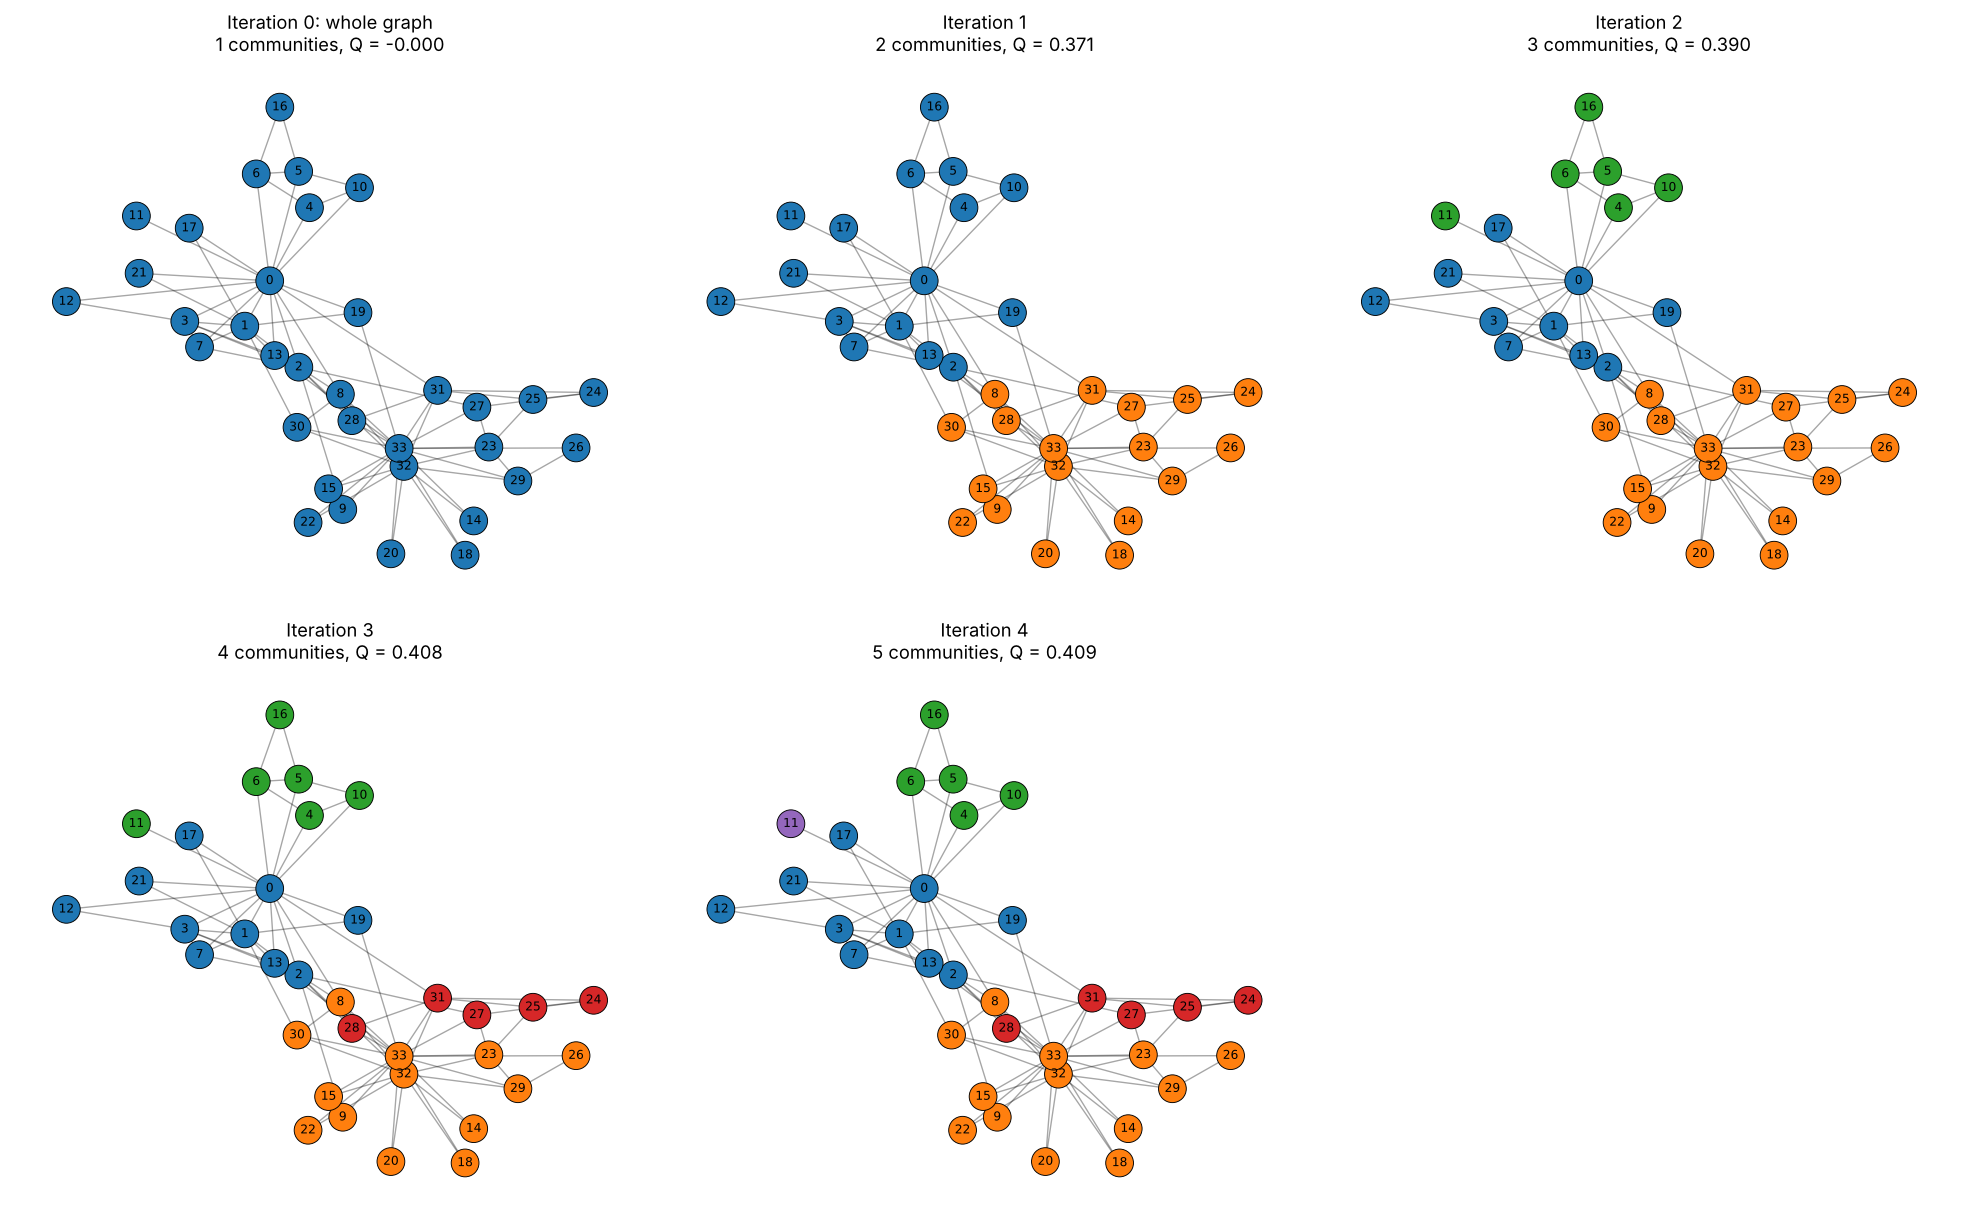

In [4]:
pos = nx.spring_layout(G, seed=42)              # fixed layout reused everywhere
palette = plt.get_cmap("tab10").colors

n_iter = len(history)
ncols = 3
nrows = int(np.ceil(n_iter / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5.6 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, h in zip(axes, history):
    colors = [palette[h["label"][v] % len(palette)] for v in nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.9)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=330,
                           edgecolors="black", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
    title = "Iteration 0: whole graph" if h["iteration"] == 0 else f"Iteration {h['iteration']}"
    ax.set_title(f"{title}\n{len(h['communities'])} communities, Q = {h['Q']:.3f}")
    ax.axis("off")
for ax in axes[n_iter:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Node metrics inside communities
The handout asks us to track four NetworkX metrics: `degree_centrality`, `betweenness_centrality`, `closeness_centrality` and `clustering`.

If we computed them on the full graph $G$, the numbers would be the same at every iteration and there would be nothing to follow. Instead, after each split we compute every metric on the **subgraph induced by the node's own community**, i.e. `G.subgraph(C)`. Each value then says how central, or how tightly clustered, a node is *within its current community*. Iteration 0 is the unsplit graph, so it also serves as the global baseline. A node that ends up alone in its community scores 0 on every metric.

In [5]:
METRICS = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

def metrics_for_partition(communities):
    # Compute every metric inside each community's induced subgraph.
    out = {name: {} for name in METRICS}
    for C in communities:
        H = G.subgraph(C)
        for name, fn in METRICS.items():
            if len(C) == 1:
                vals = {v: 0.0 for v in C}
            else:
                vals = fn(H)
            out[name].update(vals)
    return out

# dictionary keyed by iteration number, as required by the handout
metric_history = {h["iteration"]: metrics_for_partition(h["communities"]) for h in history}

import pandas as pd
summary = pd.DataFrame({
    name: pd.Series(metric_history[len(history) - 1][name]) for name in METRICS
}).round(3)
print("Metrics at the final iteration (within-community):")
summary.head(10)

Metrics at the final iteration (within-community):


,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
0,1.000,0.354,1.000,0.361
1,0.889,0.215,0.900,0.429
2,0.556,0.007,0.692,0.900
3,0.667,0.062,0.750,0.667
7,0.444,0.000,0.643,1.000
12,0.222,0.000,0.562,1.000
13,0.444,0.000,0.643,1.000
17,0.222,0.000,0.562,1.000
19,0.222,0.000,0.562,1.000
21,0.222,0.000,0.562,1.000


## 5. How the metrics change over the iterations
Each line is one node. The five nodes with the highest degree in the full graph are drawn in colour and labelled; the other 29 are light grey for context. The table after the plots counts how often each node sits in the top 5 of each metric across all iterations.

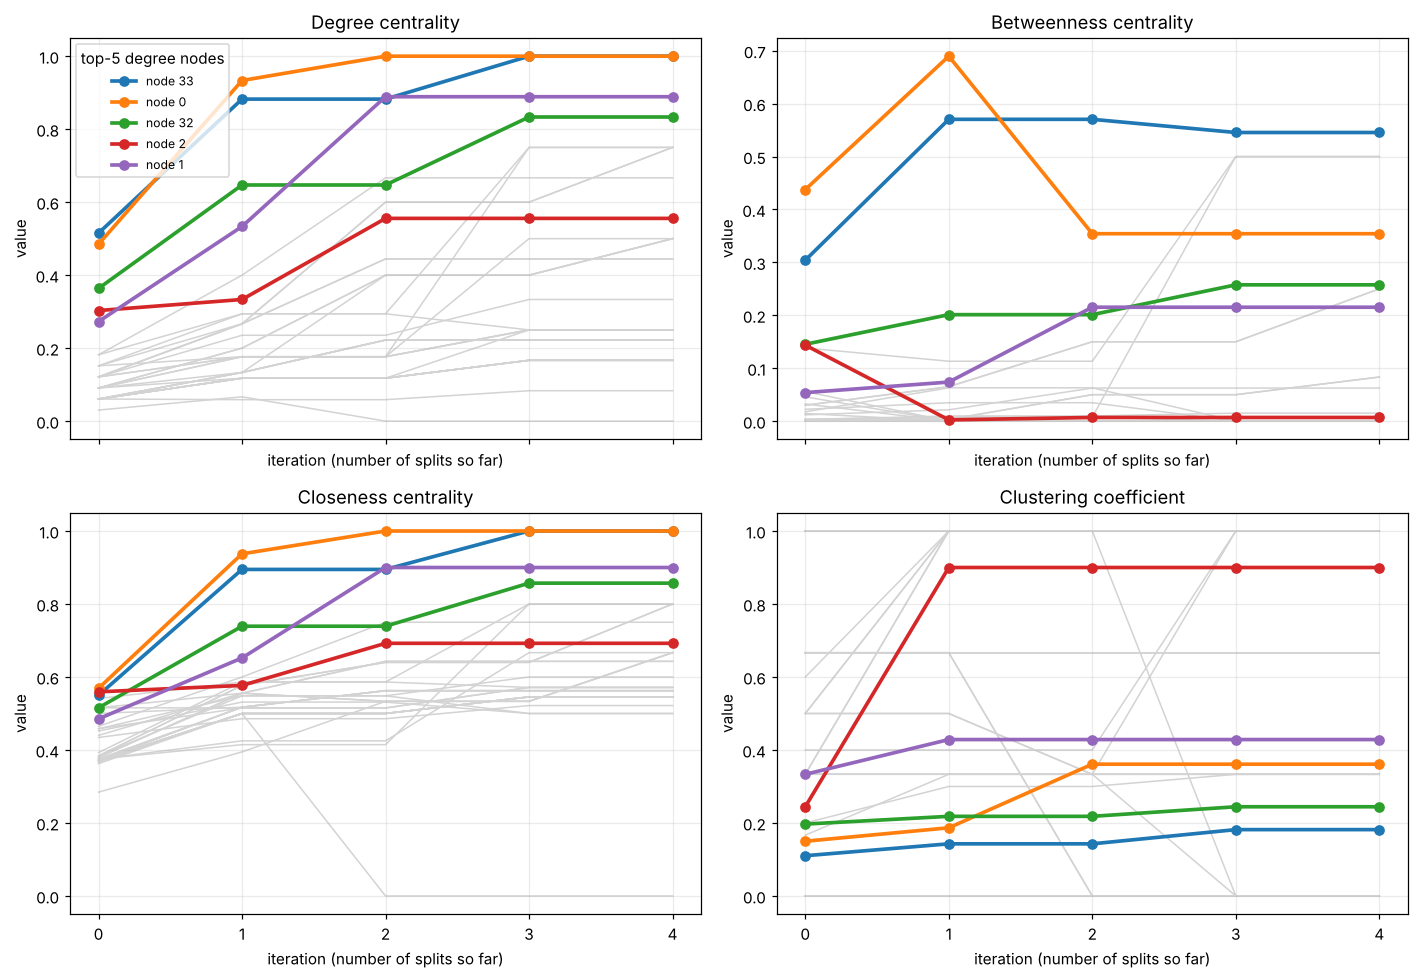

In [6]:
iters = sorted(metric_history)
global_deg = metric_history[0]["Degree centrality"]
highlight = sorted(nodes, key=lambda v: -global_deg[v])[:5]
hl_colors = dict(zip(highlight, palette))

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
for ax, name in zip(axes.ravel(), METRICS):
    for v in nodes:
        y = [metric_history[it][name][v] for it in iters]
        if v in hl_colors:
            continue
        ax.plot(iters, y, color="lightgrey", lw=1, zorder=1)
    for v in highlight:
        y = [metric_history[it][name][v] for it in iters]
        ax.plot(iters, y, color=hl_colors[v], lw=2.4, marker="o", label=f"node {v}", zorder=3)
    ax.set_title(name)
    ax.set_xticks(iters)
    ax.set_xlabel("iteration (number of splits so far)")
    ax.set_ylabel("value")
    ax.grid(alpha=0.25)
axes[0, 0].legend(title="top-5 degree nodes", fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
# Which nodes stay near the top of each ranking across *all* iterations?
TOP = 5
rows = []
for name in METRICS:
    counts = {v: 0 for v in nodes}
    for it in iters:
        ranked = sorted(nodes, key=lambda v: -metric_history[it][name][v])[:TOP]
        for v in ranked:
            counts[v] += 1
    best = sorted(nodes, key=lambda v: (-counts[v], v))[:TOP]
    rows.append({"Metric": name,
                 f"Nodes most often in top-{TOP} (appearances out of {len(iters)})":
                 ", ".join(f"{v} ({counts[v]})" for v in best)})
pd.DataFrame(rows).set_index("Metric")

,Nodes most often in top-5 (appearances out of 5)
Metric,
Degree centrality,"0 (5), 1 (5), 32 (5), 33 (5), 3 (2)"
Betweenness centrality,"0 (5), 32 (5), 33 (5), 31 (4), 1 (2)"
Closeness centrality,"0 (5), 33 (5), 1 (4), 32 (4), 3 (2)"
Clustering coefficient,"7 (5), 12 (5), 14 (5), 8 (4), 13 (4)"


## 6. Discussion

### 6.1 What the algorithm found
* **Iteration 1** divides the club into groups of 16 and 18 and reaches $Q = 0.372$. Compared with the actual fission recorded by Zachary, a single member, **node 8**, lands on the wrong side. So an algorithm that sees only the friendship edges recovers the split that really happened.
* **Later iterations** keep raising $Q$, but each gain is smaller: 0.372, 0.390, 0.408, 0.409.
* **The recursion stops at 5 communities** ($Q = 0.409$) because no remaining block has a positive leading eigenvalue.
* **The last split is nearly cosmetic.** It only separates node 11, whose single friend is node 0, and gains about 0.001 in $Q$. The meaningful picture is therefore the four-group partition from iteration 3.

### 6.2 Who stays central
The ranking table above (top 5 at each of the 5 iterations) gives three patterns.

* **The two faction leaders.** Nodes **0** (Mr. Hi) and **33** (the president) are in the top 5 for degree, betweenness and closeness at every iteration, and node **32** does the same for degree and betweenness. Splitting the graph does not dethrone them: inside their own communities they end up adjacent to everyone, with degree and closeness of 1.0 (from iteration 2 for node 0, from iteration 3 for node 33).
* **Their lieutenants.** Nodes **1** and **31** stay close behind, with node 1 high on degree and closeness and node 31 on betweenness.
* **Clustering ranks nodes differently.** Its persistent leaders are low-degree nodes such as **7, 12, 14, 8 and 13**, which sit inside tight cliques where all of their few neighbours know each other. The hubs score modestly (node 33 never exceeds 0.2) because they link several groups that do not otherwise connect.

### 6.3 How community structure shapes the metrics
1. **Values depend on community size.** Every metric is normalised by the size of the community it is computed in, so raw numbers jump after a split. Node 0's betweenness, for example, is 0.44 on the whole graph, 0.69 after the first split and 0.35 from iteration 2 on. Rankings are therefore a safer basis for comparison across iterations than raw values.
2. **Hubs become local hubs.** In a small community the hub reaches everyone directly, so its degree and closeness saturate at 1.0.
3. **Bridges lose their role.** The most heavily used paths in the full graph are the edges between factions. Once we cut along community boundaries those paths disappear, and betweenness inside a community only reflects how a node joins sub-groups of that community.
4. **Clustering goes up.** Removing sparse cross-community edges leaves denser groups. Node 0's clustering rises from 0.15 on the whole graph to 0.36 within its own community.

### 6.4 Limitations
* **Restricted modularity matrix.** Following the handout, we use the plain block $B_{ij}$ with $i,j\in C$. Newman's generalised version also subtracts $\delta_{ij}\sum_{l\in C}B_{il}$ on the diagonal, which makes the $\lambda_1 \le 0$ test exact for the true change $\Delta Q$. The recursion still terminates cleanly with the simpler block, but the later splits (iterations 3 and 4) are the most likely to change under the generalised version.
* **Sign rule.** Eigenvector entries equal to 0 are assigned to the negative group. This choice can matter in principle, though the result is deterministic for this graph.

## References
1. M. E. J. Newman, "Modularity and community structure in networks," *PNAS* 103(23):8577-8582, 2006.
2. W. W. Zachary, "An information flow model for conflict and fission in small groups," *Journal of Anthropological Research* 33(4):452-473, 1977.
3. A. Hagberg, D. Schult, P. Swart, "Exploring network structure, dynamics, and function using NetworkX," *SciPy 2008*.